# Path A, P25 visuals — humans vs. our model on the training cells (Oct 30, 2026)

**Spec (as given):**

TASK: Build ONE notebook, notebooks/path1/p25_visuals.ipynb, comparing humans with our model on the training cells Hierarchy (EL, CL, CC) and Full (CL, CC). Descriptive only: no decisions, no refits. Never load Ring/CT.

- Simulated runs (re-simulated; the saved parquet only holds statistics): **final**: replicates 1–20 with the seed-4001 streams; check that their fast-path statistics EXACTLY equal the saved rows of results/tables/p24_reps_final.parquet for those replicates; stop if they don't. **Published APEM** (descriptive reference, labeled "published APEM on our interface"): preset APEM, a = 0.5, s = 0.5, mu = 0.1 for both lab and cloud; 20 replicates, seed 5001. Design: the L3/L5 designs, restricted to the 5 cells. Human runs: L3 (targets 1–7) and L5 (targets 8–10), same filters as the targets.
- Fig 1, check overview (p24_checks.csv): one panel per cell; rows = the check statistics of that cell (targets 1–10, 10c marked "trigger only"); x = (sim mean − human value) / CI half-width, replaced CIs where the zero-width rule applied; band [−1, 1]; markers final (filled), L1 (hollow), L0 (x); clip at ±10 and label the true value.
- Fig 2, Tabor Fig. 4/5-style averaged normalized trajectories: the paper's branch definitions (Left Branch, Right Branch, Apex), time normalization, Agreement sign convention, thick = position, thin = Agreement. Hierarchy = successful rounds with > 10% fraught; Full = successful rounds; CL cells. Grid 2 rows (Hierarchy, Full) x 3 columns (Humans, final, published APEM), n in each panel. If a model panel has < 100 qualifying runs, simulate more replicates (same seed stream, up to 100) for that panel only, and state this.
- Fig 3, time to consensus (KM) per cell: humans (Greenwood 95% band), final (pooled over replicates), published APEM; each curve's median marked.
- Fig 4, Agreement at reversal (target 9: A in the row before the event) per cell: humans vs. final vs. published APEM; vertical lines at the medians.
- Fig 5 (bonus), example rounds: one human Hierarchy CL round with a fraught phase and one final-model Hierarchy CL round with a fraught phase (first qualifying round in replicate order); all 7 sliders over time, colored by branch, shaded where fraught.
- Figures: results/figures/p25_vis_figN.png; under each, 2–3 lines "how to read it".

**Implementation notes:**
- "Replicates 1–20" = the first 20 replicates of the main run, numbered 0–19 in the parquet (batch 0, seed [4001, 0, 0] in scripts/p24_main.py). They are simulated on the **full** L3 design (6 cells), because each round's stream is its position in that design; only the 5 cells are analysed. Extra replicates for Fig 2 are batches b = 1, 2, … (seed [4001, b, 20 b]: replicates 20 b … 20 b + 19, the main run's own), simulated for that panel's rounds only (`visuals.simulate_rows`, the same streams as in the full design).
- Published APEM: the same batch seeds with 5001 ([5001, b, 20 b]), on the L3 design restricted to the 5 cells; no group effect, no motion rates, no reversal script (preset APEM).
- Fig 2 is a port of the authors' averaging analysis (OSF `Code/runapem.m`: time warp, selection, flip, branch swap, Agreement); the repo had no Python version of it, only its pieces (`fraught.fraught_percent_interp`, `apem_osf.warp`). Rounds: L3 (humans) and the L3 design (models). Details in `src/slider/visuals.py`.
- Fig 3 uses L3 rounds (failures censored at the time limit, as target 2); Fig 4 uses L5 rounds (human) and the L5 rounds of each replicate (non-whole-second), as target 9.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from slider import config, design, sim, targets
from slider import visuals as V
from slider import slider_logs as sl
from slider.fraught import fraught_mask, fraught_percent_interp

pd.set_option("display.width", 220)
SURFACE, INK, INK_2, GRID, BAND = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#ebeae6"
COL = {"humans": INK, "final": "#2a78d6", "APEM": "#eb6834", "L1": "#1baf7a", "L0": INK_2}
NAME = {"humans": "humans", "final": "final model", "APEM": "published APEM on our interface"}
BRANCH = {"Apex": (0.8, 0, 0), "Left Branch": (0.5, 0.5, 0), "Right Branch": (0.5, 0, 0.5)}   # runapem.m colours
SIENNA = (160 / 256, 82 / 256, 45 / 256)
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
                     "axes.titlecolor": INK, "font.size": 10})


def fig_path(n):
    return config.FIGURES / f"p25_vis_fig{n}.png"

## Data

Human runs: L3 (outcome, train + val) and L5 (behavior, train + val, no bot runs, complete).

In [2]:
runs3_h, table3_h = design.load("L3")
runs5_h, _ = design.load("L5")
hum = V.collect(runs3_h, table3_h, runs5_h, keep_first=("Hierarchy", "CL"))
print("human rounds per cell:", hum["km"].groupby(["topology", "dataset"]).size().to_dict())
print("reversals per cell:", hum["rev"].groupby(["topology", "dataset"]).size().to_dict())

human rounds per cell: {('Full', 'CC'): 36, ('Full', 'CL'): 63, ('Hierarchy', 'CC'): 40, ('Hierarchy', 'CL'): 61, ('Hierarchy', 'EL'): 51}
reversals per cell: {('Full', 'CC'): 1245, ('Full', 'CL'): 2864, ('Hierarchy', 'CC'): 940, ('Hierarchy', 'CL'): 1229, ('Hierarchy', 'EL'): 1610}


**final, replicates 0–19 (batch 0, seed [4001, 0, 0]), and the exact-equality check** against `p24_reps_final.parquet` (the 53 statistics, 10c and the per-group reversal rates of each replicate). The notebook stops if any replicate differs.

In [3]:
d3 = design.design("L3")
roles, keep5 = list(d3["role"]), ~d3["whole_second"].to_numpy()
saved = pd.read_parquet(config.P24_REPS["final"])
KEYS = ["replicate", "target", "stat", "topology", "dataset", "group"]
CELL_HCL = ("Hierarchy", "CL")


def same_rows(a, b):
    a = a.sort_values(KEYS).reset_index(drop=True)
    b = b.sort_values(KEYS).reset_index(drop=True)
    if len(a) != len(b) or not (a[KEYS].astype(str).to_numpy() == b[KEYS].astype(str).to_numpy()).all():
        return False
    va, vb = a["value"].to_numpy(float), b["value"].to_numpy(float)
    return bool(np.all((va == vb) | (np.isnan(va) & np.isnan(vb))))


start = time.time()
seed0 = V.batch_seed(4001, 0)
rounds = design.simulate_rounds(d3, "final", R=20, seed=seed0)
fin, equal, example_final = [], [], None
for r in range(20):
    runs3 = design.copy_runs(d3, rounds, r, seed0)
    table3 = sim.table(runs3, roles)
    runs5 = [run for run, k in zip(runs3, keep5) if k]
    st = targets.check_stats(runs3, table3, runs5).assign(replicate=r)
    st = st[st["in_check_list"] | st["stat"].isin([targets.PAUSE_SHARE, targets.GROUP_RATE])]
    equal.append(same_rows(st[KEYS + ["value"]], saved.loc[saved["replicate"] == r, KEYS + ["value"]]))
    part = V.collect(runs3, table3, runs5, keep_first=CELL_HCL if example_final is None else None)
    if example_final is None and part["first"] is not None:
        example_final = (part["first"][0], {**part["first"][1], "replicate": r})
    fin.append(part)
    for out, _ in rounds:
        out[r] = None                                            # copy r is done
del rounds
print(f"replicates 0-19 equal to the saved rows: {sum(equal)} of 20  ({(time.time() - start) / 60:.1f} min)")
assert all(equal), f"STOP: replicates {[r for r, e in enumerate(equal) if not e]} differ from p24_reps_final.parquet"

replicates 0-19 equal to the saved rows: 20 of 20  (15.3 min)


**Published APEM on our interface** (a = 0.5, s = 0.5, mu = 0.1 everywhere), replicates 0–19 (seed [5001, 0, 0]), the L3 design restricted to the 5 cells.

In [4]:
d5 = d3[V.in_cells(d3)].reset_index(drop=True)
seedA = V.batch_seed(5001, 0)
start = time.time()
rounds = design.simulate_rounds(d5, "APEM", R=20, seed=seedA, **V.APEM_PUBLISHED)
keep5_A = ~d5["whole_second"].to_numpy()
apem = []
for r in range(20):
    runs3 = design.copy_runs(d5, rounds, r, seedA)
    runs5 = [run for run, k in zip(runs3, keep5_A) if k]
    apem.append(V.collect(runs3, sim.table(runs3, list(d5["role"])), runs5))
    for out, _ in rounds:
        out[r] = None
del rounds
print(f"{len(d5)} rounds x 20 replicates ({(time.time() - start) / 60:.1f} min)")
FIN, APEM = V.merge(fin), V.merge(apem)
print("final: rounds per cell", FIN["km"].groupby(["topology", "dataset"]).size().to_dict())
print("APEM:  rounds per cell", APEM["km"].groupby(["topology", "dataset"]).size().to_dict())

251 rounds x 20 replicates (4.4 min)


final: rounds per cell {('Full', 'CC'): 720, ('Full', 'CL'): 1260, ('Hierarchy', 'CC'): 800, ('Hierarchy', 'CL'): 1220, ('Hierarchy', 'EL'): 1020}
APEM:  rounds per cell {('Full', 'CC'): 720, ('Full', 'CL'): 1260, ('Hierarchy', 'CC'): 800, ('Hierarchy', 'CL'): 1220, ('Hierarchy', 'EL'): 1020}


**Fig 2 panels with < 100 qualifying rounds:** more replicates of that panel's rounds only (batches 1–4, the main-run streams), up to 100 replicates.

In [5]:
def extend(merged, design_, preset, seed, **kw):
    """Add batches b = 1, 2, ... (replicates 20 b ... 20 b + 19) of a Fig 2 cell until it has >= 100 qualifying
    rounds or 100 replicates. Returns {cell: replicates used}."""
    used = {}
    for cell in [("Hierarchy", "CL"), ("Full", "CL")]:
        n_rep = 20
        rows = np.flatnonzero(((design_["topology"] == cell[0]) & (design_["dataset"] == cell[1])).to_numpy())
        while merged["traj"].get(cell, [0, 0, 0])[2] < 100 and n_rep < 100:
            b = n_rep // 20
            sub, rr = V.simulate_rows(design_, rows, preset, R=20, seed=V.batch_seed(seed, b), **kw)
            for r in range(20):
                runs = design.copy_runs(sub, rr, r, V.batch_seed(seed, b))
                t = V.trajectories(runs, sim.table(runs, list(sub["role"])), [cell])
                if cell in t:
                    acc = merged["traj"].setdefault(cell, [0.0, 0.0, 0])
                    acc[0], acc[1], acc[2] = acc[0] + t[cell][0], acc[1] + t[cell][1], acc[2] + t[cell][2]
            n_rep += 20
        used[cell] = n_rep
    return used


start = time.time()
REPS = {"final": extend(FIN, d3, "final", 4001), "APEM": extend(APEM, d5, "APEM", 5001, **V.APEM_PUBLISHED)}
n_traj = pd.DataFrame({name: {f"{c[0]} {c[1]}": f"{m['traj'].get(c, [0, 0, 0])[2]} rounds ({REPS[name][c] if name in REPS else '-'} replicates)"
                               for c in [("Hierarchy", "CL"), ("Full", "CL")]}
                       for name, m in [("humans", hum), ("final", FIN), ("APEM", APEM)]})
print(f"({(time.time() - start) / 60:.1f} min)")
n_traj

(0.0 min)


,humans,final,APEM
Hierarchy CL,16 rounds (- replicates),211 rounds (20 replicates),312 rounds (20 replicates)
Full CL,52 rounds (- replicates),395 rounds (20 replicates),195 rounds (20 replicates)


## Fig 1 — check overview (from `p24_checks.csv`; no new simulation)

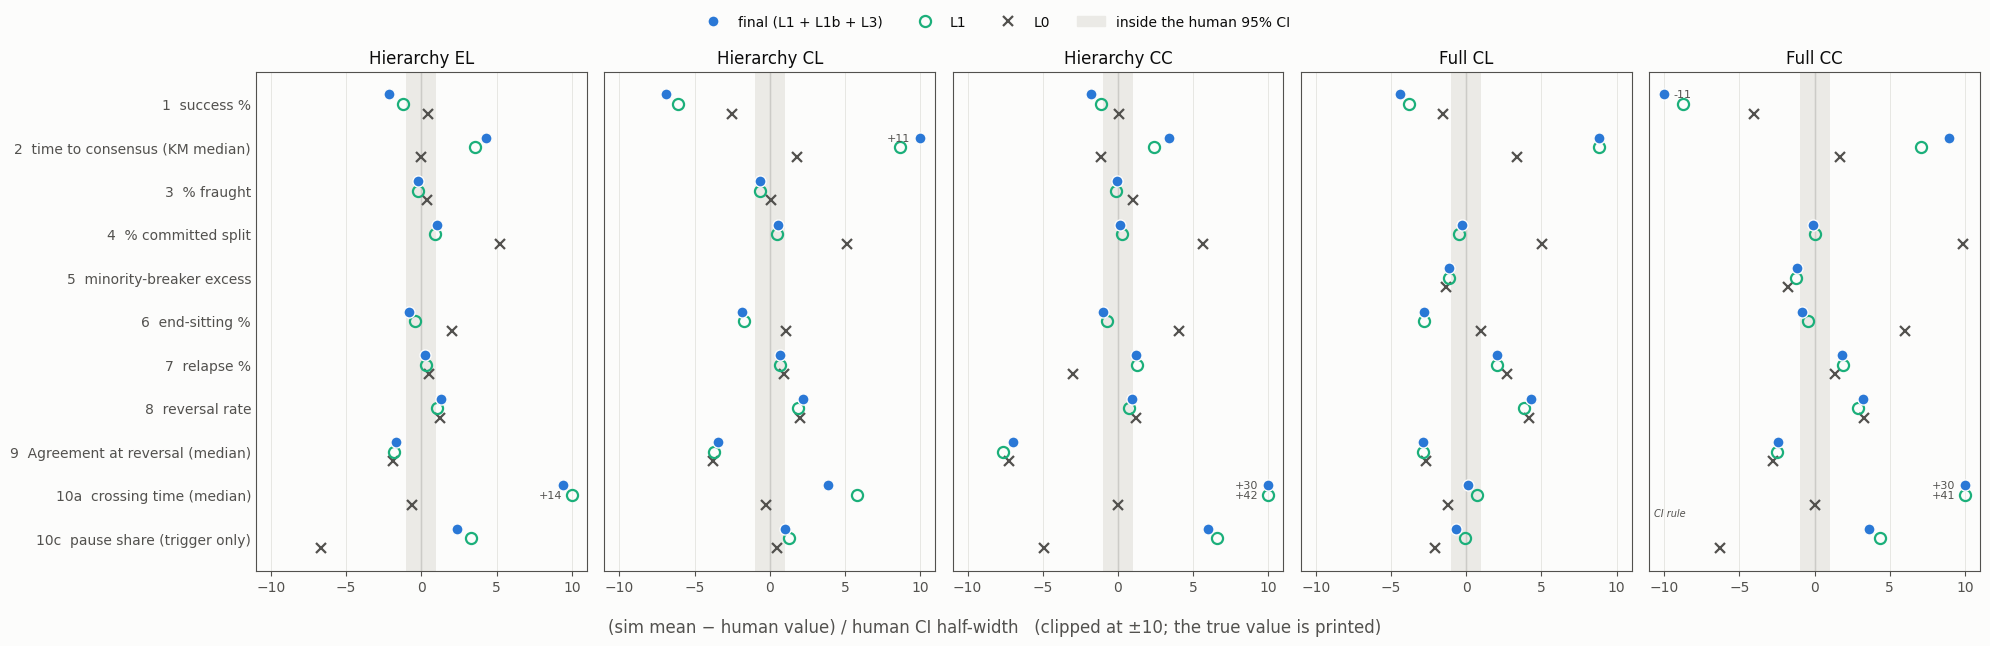

In [6]:
chk = pd.read_csv(config.P24_CHECKS)
chk["gap"] = (chk["sim_mean"] - chk["human"]) / ((chk["ci_hi"] - chk["ci_lo"]) / 2)
ROWS = [(1, "success_rate_pct", "1  success %"), (2, "consensus_time_km_median_s", "2  time to consensus (KM median)"),
        (3, "fraught_pct_mean", "3  % fraught"), (4, "committed_pct_mean", "4  % committed split"),
        (5, "breaker_excess", "5  minority-breaker excess"), (6, "end_sitting_pct", "6  end-sitting %"),
        (7, "relapse_pct", "7  relapse %"), (8, "reversal_rate", "8  reversal rate"),
        (9, "f_rev_median", "9  Agreement at reversal (median)"), (10, "crossing_time_median_s", "10a  crossing time (median)"),
        (10, "pause_share_pct", "10c  pause share (trigger only)")]
MARK = {"final": dict(marker="o", markersize=8, markerfacecolor=COL["final"], markeredgecolor=SURFACE, markeredgewidth=1),
        "L1": dict(marker="o", markersize=8, markerfacecolor="none", markeredgecolor=COL["L1"], markeredgewidth=1.6),
        "L0": dict(marker="x", markersize=7, markeredgecolor=COL["L0"], markeredgewidth=1.6)}
OFFSET = {"final": -0.22, "L1": 0.0, "L0": 0.22}

fig, axes = plt.subplots(1, 5, figsize=(20, 6.4), sharey=True)
for ax, (top, ds) in zip(axes, V.CELLS):
    ax.axvspan(-1, 1, color=BAND, zorder=0, linewidth=0)
    ax.axvline(0, color=INK_2, linewidth=0.8, zorder=1)
    for y, (t, s, _) in enumerate(ROWS):
        for preset in ["L0", "L1", "final"]:
            row = chk[(chk["preset"] == preset) & (chk["target"] == t) & (chk["stat"] == s) &
                      (chk["topology"] == top) & (chk["dataset"] == ds)]
            if len(row) == 0:
                continue
            g = row["gap"].iloc[0]
            x, yy = float(np.clip(g, -10, 10)), y + OFFSET[preset]
            ax.plot([x], [yy], linestyle="none", zorder=3, **MARK[preset])
            if abs(g) > 10:
                ax.annotate(f"{g:+.0f}", (x, yy), xytext=(-7 if g > 0 else 7, 0), textcoords="offset points",
                            ha="right" if g > 0 else "left", va="center", fontsize=8, color=INK_2)
            if preset == "final" and isinstance(row["ci_rule"].iloc[0], str):
                ax.annotate("CI rule", (-10.7, y + 0.42), fontsize=7, color=INK_2, va="center", style="italic")
    ax.set_xlim(-11, 11)
    ax.set_xticks([-10, -5, 0, 5, 10])
    ax.set_title(f"{top} {ds}")
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(ROWS)))
axes[0].set_yticklabels([r[2] for r in ROWS])
axes[0].invert_yaxis()
handles = [Line2D([], [], linestyle="none", label=lab, **MARK[p]) for p, lab in
           [("final", "final (L1 + L1b + L3)"), ("L1", "L1"), ("L0", "L0")]] + [Patch(color=BAND, label="inside the human 95% CI")]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.supxlabel("(sim mean − human value) / human CI half-width   (clipped at ±10; the true value is printed)", color=INK_2)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(fig_path(1), dpi=150)
plt.show()

**How to read it.** Each row is one check statistic; a marker inside the grey band means the model's mean (200 replicates) lies inside the human 95% CI, right of 0 = the model is higher than humans. The distance is in CI half-widths, so +3 means three half-widths above the human value; points beyond ±10 sit on the edge with their true value printed. "CI rule" marks the CIs replaced by the zero-width rule (Clopper-Pearson / lab clock ± 0.05 s).

## Fig 2 — averaged normalized trajectories (Tabor et al. Fig. 4/5 style; CL cells)

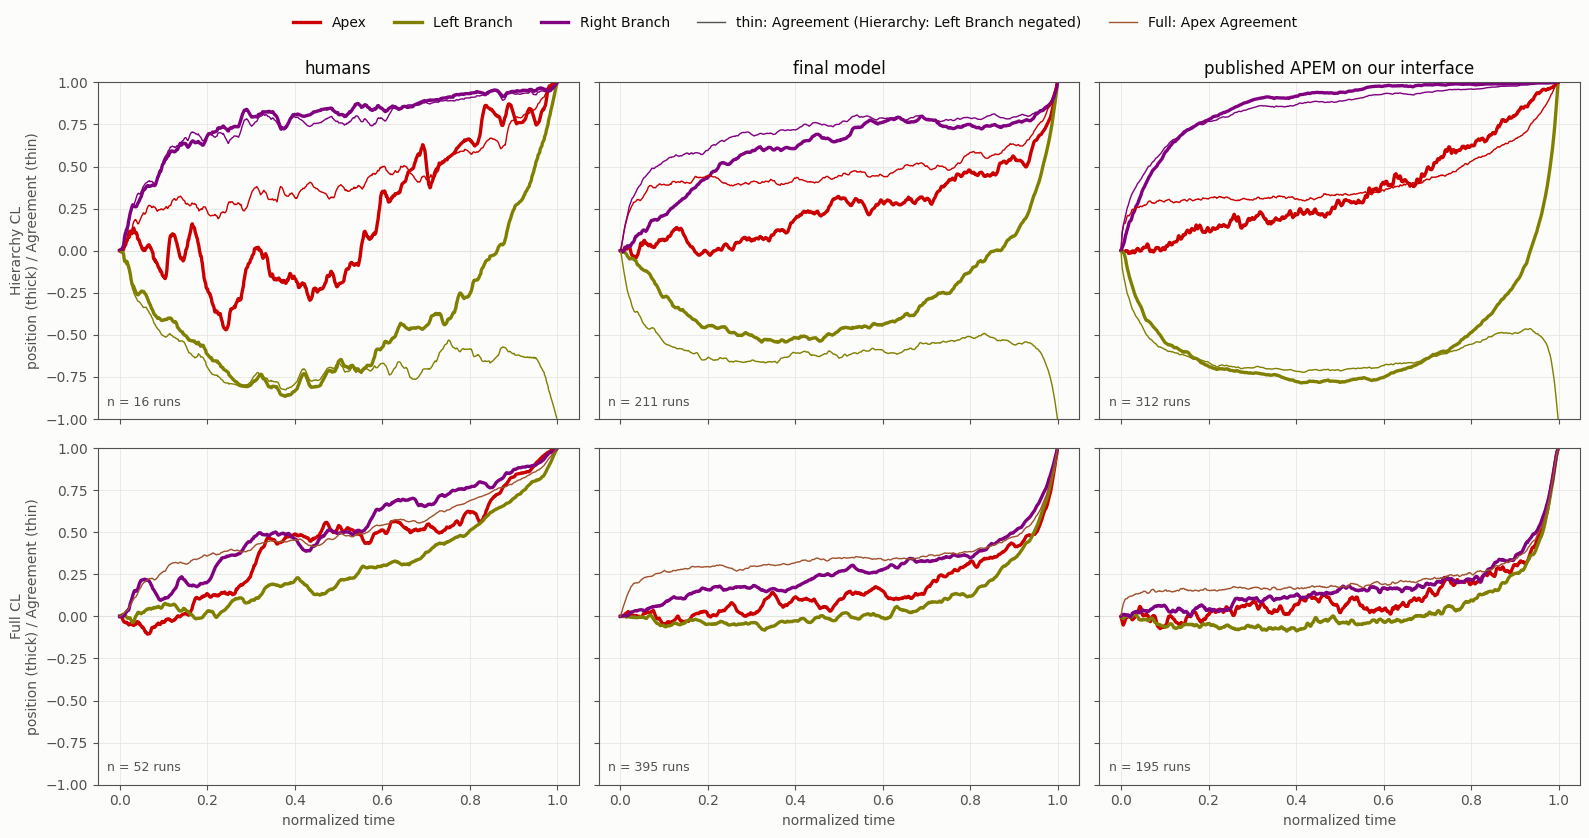

In [7]:
tvals = np.arange(V.NWARP + 1) / (V.NWARP + 1)                     # runapem.m: (0:nwarp) / (nwarp + 1)
cols = [("humans", hum), ("final", FIN), ("APEM", APEM)]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4), sharex=True, sharey=True)
for i, top in enumerate(["Hierarchy", "Full"]):
    for j, (name, src) in enumerate(cols):
        ax = axes[i, j]
        x_sum, a_sum, n = src["traj"].get((top, "CL"), [None, None, 0])
        ax.axhline(0, color=GRID, linewidth=0.8)
        if n > 0:
            gm, am = V.group_means(x_sum / n), V.group_means(a_sum / n)
            for k, (label, colour) in enumerate(BRANCH.items()):
                ax.plot(tvals, gm[:, k], color=colour, linewidth=2.4)
            if top == "Hierarchy":
                am[:, 1] = -am[:, 1]                                       # runapem.m: reverse the Left Branch's Agreement
                for k, colour in enumerate(BRANCH.values()):
                    ax.plot(tvals, am[:, k], color=colour, linewidth=1)
            else:
                ax.plot(tvals, am[:, 0], color=SIENNA, linewidth=1)        # Full: the Apex's Agreement only
        extra = ""
        if name in REPS and REPS[name][(top, "CL")] > 20:
            extra = f" ({REPS[name][(top, 'CL')]} replicates)"
        ax.text(0.02, 0.04, f"n = {n} runs{extra}", transform=ax.transAxes, color=INK_2, fontsize=9)
        ax.set_ylim(-1, 1)
        ax.grid(color=GRID, linewidth=0.5)
        if i == 0:
            ax.set_title(NAME[name])
    axes[i, 0].set_ylabel(f"{top} CL\nposition (thick) / Agreement (thin)")
for ax in axes[1]:
    ax.set_xlabel("normalized time")
handles = [Line2D([], [], color=c, linewidth=2.4, label=l) for l, c in BRANCH.items()]
handles += [Line2D([], [], color=INK_2, linewidth=1, label="thin: Agreement (Hierarchy: Left Branch negated)"),
            Line2D([], [], color=SIENNA, linewidth=1, label="Full: Apex Agreement")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(fig_path(2), dpi=150)
plt.show()

**How to read it.** Each panel averages the qualifying rounds after stretching every round to the same length (0 = start, 1 = consensus) and flipping it so the winning side is +1. Thick lines are mean positions of the Apex, the Left Branch (by construction the branch that ends up switching) and the Right Branch; thin lines are their Agreement (Left Branch negated, as in the paper). A Left Branch that dips below 0 and comes back is the escape from a fraught state; compare its depth and timing across columns.

## Fig 3 — time to consensus (Kaplan-Meier)

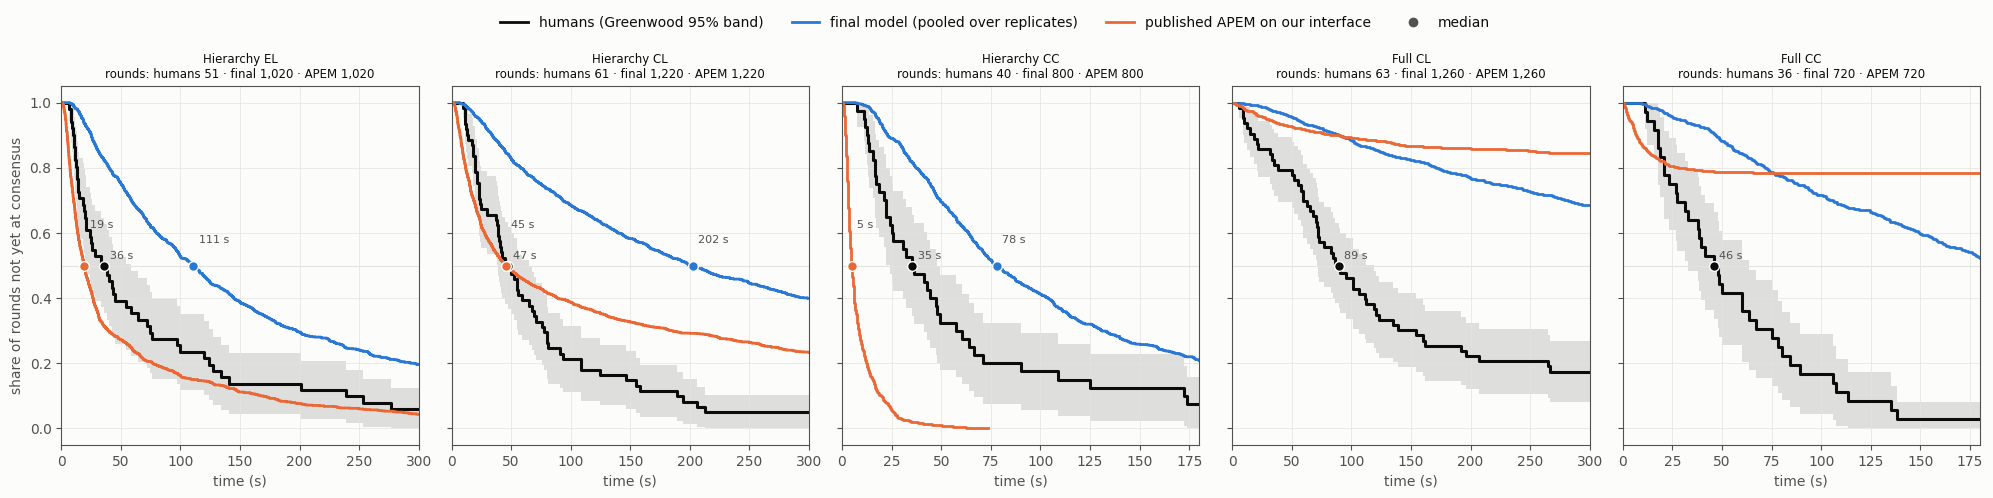

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5.0), sharey=True)
n_km = {}
for ax, (top, ds) in zip(axes, V.CELLS):
    limit = config.TIME_LIMIT["cloud" if ds == "CC" else "lab"]
    for name, src in [("humans", hum), ("final", FIN), ("APEM", APEM)]:
        d = src["km"][(src["km"]["topology"] == top) & (src["km"]["dataset"] == ds)]
        km, median = V.km_band(d["ttc"], d["event"])
        tt, ss = np.r_[0, km["time"]], np.r_[1, km["survival"]]
        ax.step(tt, ss, where="post", color=COL[name], linewidth=2 if name != "humans" else 2.2)
        if name == "humans":
            ax.fill_between(tt, np.r_[1, km["lo"]], np.r_[1, km["hi"]], step="post", color=COL[name], alpha=0.12, linewidth=0)
        if not np.isnan(median):
            ax.plot([median], [0.5], marker="o", markersize=7, color=COL[name], markeredgecolor=SURFACE, zorder=4)
            ax.annotate(f"{median:.0f} s", (median, 0.5), xytext=(4, 5 + 11 * ["humans", "final", "APEM"].index(name)),
                        textcoords="offset points", fontsize=8, color=INK_2)
        n_km[(f"{top} {ds}", name)] = len(d)
    ax.axhline(0.5, color=GRID, linewidth=0.8)
    ax.set_xlim(0, limit)
    n = [n_km[(f"{top} {ds}", m)] for m in ["humans", "final", "APEM"]]
    ax.set_title(f"{top} {ds}\nrounds: humans {n[0]:,} · final {n[1]:,} · APEM {n[2]:,}", fontsize=8.5)
    ax.set_xlabel("time (s)")
    ax.grid(color=GRID, linewidth=0.5)
axes[0].set_ylabel("share of rounds not yet at consensus")
handles = [Line2D([], [], color=COL[m], linewidth=2, label=NAME[m] + (" (Greenwood 95% band)" if m == "humans" else
           " (pooled over replicates)" if m == "final" else "")) for m in ["humans", "final", "APEM"]]
handles += [Line2D([], [], linestyle="none", marker="o", color=INK_2, label="median")]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(fig_path(3), dpi=150)
plt.show()

**How to read it.** Each curve is the share of rounds still without consensus at time t (failures count as still running until the time limit, the x-axis end). The shaded band is the humans' Greenwood 95% band; dots mark the medians (no dot: fewer than half the rounds reach consensus). A curve that ends high means many failed rounds; a curve left of the humans means faster consensus.

## Fig 4 — where reversals happen: Agreement at reversal

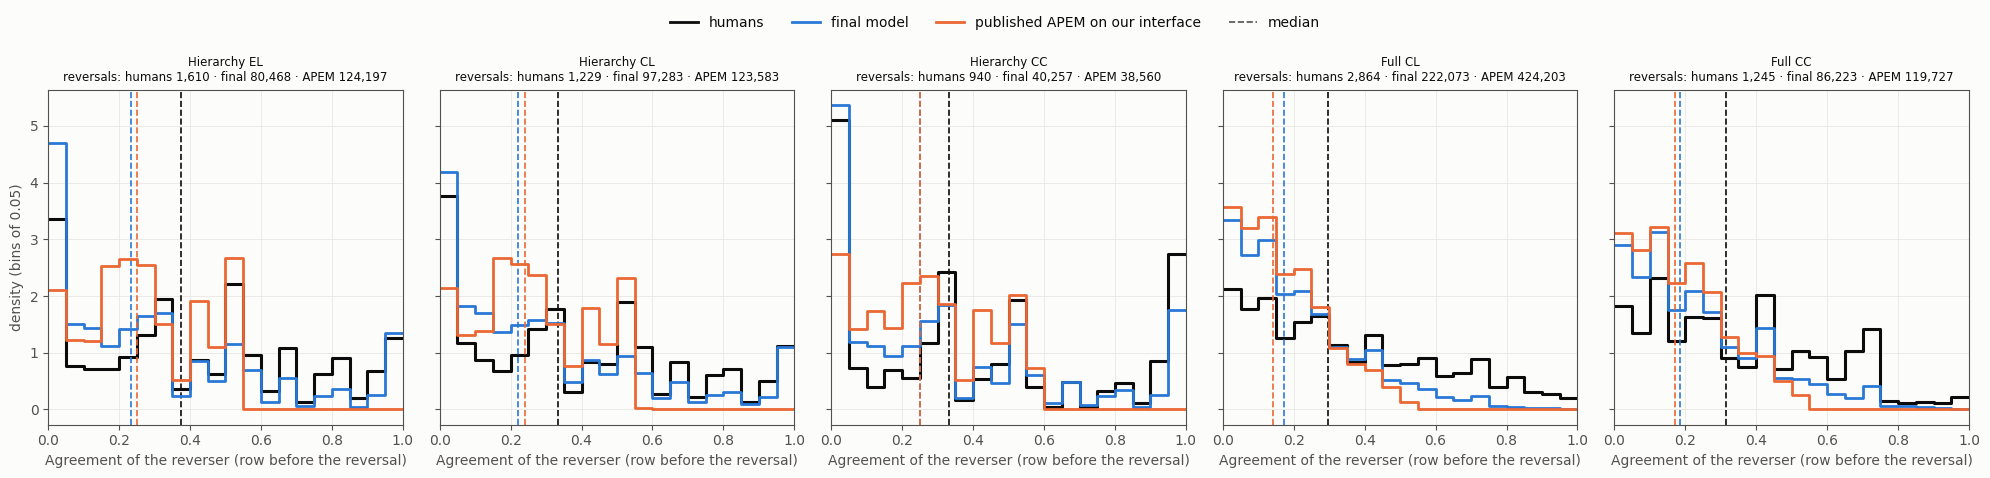

In [9]:
bins = np.linspace(0, 1, 21)
fig, axes = plt.subplots(1, 5, figsize=(20, 4.8), sharey=True)
n_rev = {}
for ax, (top, ds) in zip(axes, V.CELLS):
    for name, src in [("humans", hum), ("final", FIN), ("APEM", APEM)]:
        a = src["rev"].loc[(src["rev"]["topology"] == top) & (src["rev"]["dataset"] == ds), "A"].to_numpy(float)
        dens, _ = np.histogram(a, bins=bins, density=True)
        ax.step(bins, np.r_[dens, dens[-1]], where="post", color=COL[name], linewidth=2 if name != "humans" else 2.2)
        med = targets.describe_A(a)[0]
        ax.axvline(med, color=COL[name], linestyle="--", linewidth=1.2)
        n_rev[(f"{top} {ds}", name)] = len(a)
    n = [n_rev[(f"{top} {ds}", m)] for m in ["humans", "final", "APEM"]]
    ax.set_title(f"{top} {ds}\nreversals: humans {n[0]:,} · final {n[1]:,} · APEM {n[2]:,}", fontsize=8.5)
    ax.set_xlabel("Agreement of the reverser (row before the reversal)")
    ax.set_xlim(0, 1)
    ax.grid(color=GRID, linewidth=0.5)
axes[0].set_ylabel("density (bins of 0.05)")
handles = [Line2D([], [], color=COL[m], linewidth=2, label=NAME[m]) for m in ["humans", "final", "APEM"]]
handles += [Line2D([], [], color=INK_2, linewidth=1.2, linestyle="--", label="median")]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(fig_path(4), dpi=150)
plt.show()

**How to read it.** For every reversal, the reverser's Agreement A (0 = its neighbourhood is split evenly, 1 = everyone around it sits at the same end) in the row before the reversal; dashed lines are the medians (target 9's statistic). Mass to the left means reversals happen when the neighbourhood disagrees; a model curve left of the humans reverses in more conflicted states than people do.

## Fig 5 — example rounds (Hierarchy CL, with a fraught phase)

human: {'file': 'log_Fri Sep 16 161000 EDT 2016.txt', 'wave': 2, 'success': True, 'fraught_pct': 21.178821178821178}
final: {'file': 'sim0_log_Mon Sep 19 164446 EDT 2016.txt', 'wave': 2, 'success': False, 'fraught_pct': 10.18981018981019, 'replicate': 0}


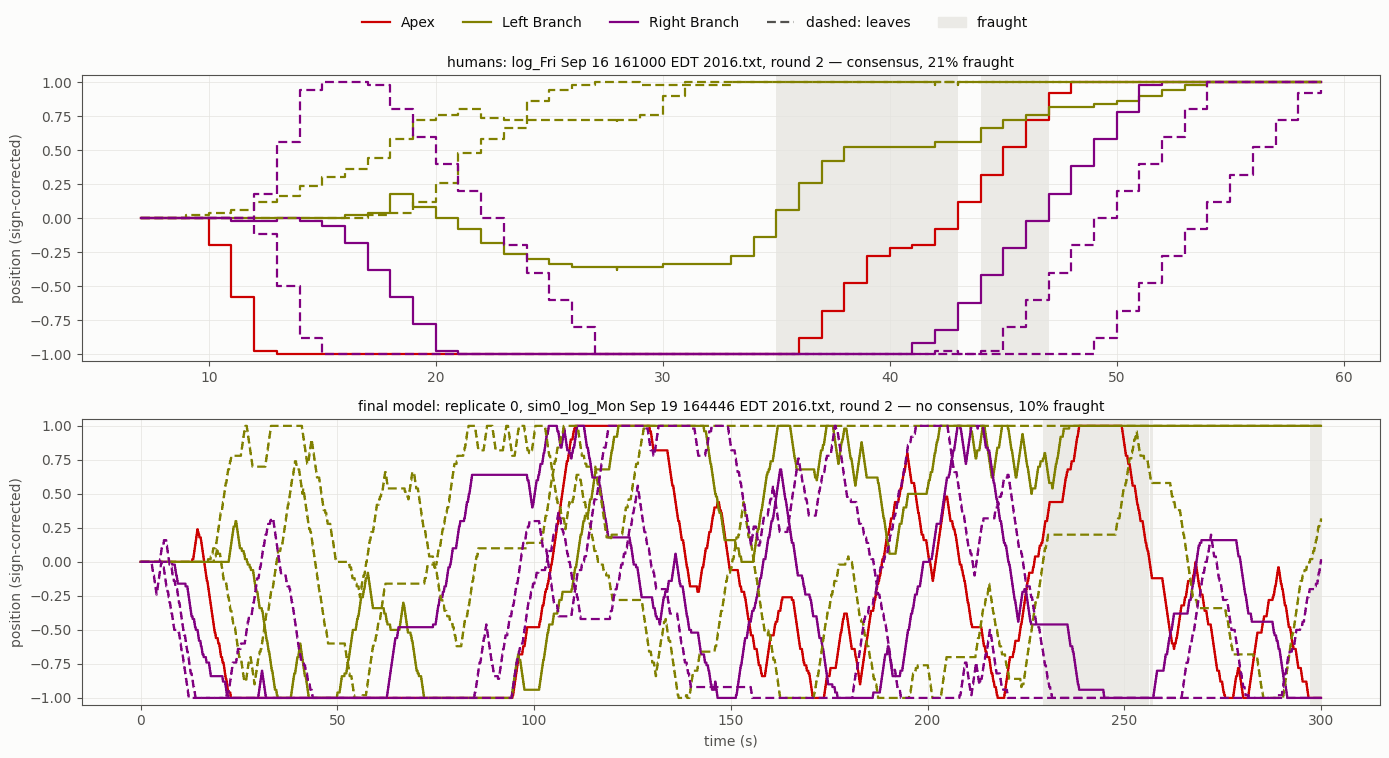

In [10]:
ex_h = hum["first"]
ex_f = example_final
print("human:", ex_h[1])
print("final:", ex_f[1])
NODE_BRANCH = {0: "Apex", 1: "Left Branch", 3: "Left Branch", 4: "Left Branch",
               2: "Right Branch", 5: "Right Branch", 6: "Right Branch"}            # graph nodes, no swap

fig, axes = plt.subplots(2, 1, figsize=(14, 7.6), sharey=True)
for ax, (run, info), title in [(axes[0], ex_h, "humans"), (axes[1], ex_f, "final")]:
    t, x = run["t"], V.node_positions(run, "Hierarchy")
    mask = fraught_mask(run)
    t_end = t[-1]
    edges = np.append(t, t_end)
    start_ = None
    for k in range(len(t) + 1):                                    # shade fraught rows (each holds until the next)
        on = k < len(t) and mask[k]
        if on and start_ is None:
            start_ = edges[k]
        if not on and start_ is not None:
            ax.axvspan(start_, edges[k], color=BAND, linewidth=0, zorder=0)
            start_ = None
    for node in range(7):
        ax.step(t, x[:, node], where="post", color=BRANCH[NODE_BRANCH[node]], linewidth=1.6,
                linestyle="-" if node < 3 else (0, (4, 2)))
    where = f"replicate {info['replicate']}, " if "replicate" in info else ""
    ax.set_title(f"{NAME[title]}: {where}{info['file']}, round {info['wave']} — "
                 f"{'consensus' if info['success'] else 'no consensus'}, {info['fraught_pct']:.0f}% fraught", fontsize=10)
    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel("position (sign-corrected)")
    ax.grid(color=GRID, linewidth=0.5)
axes[1].set_xlabel("time (s)")
handles = [Line2D([], [], color=c, linewidth=1.6, label=l) for l, c in BRANCH.items()]
handles += [Line2D([], [], color=INK_2, linewidth=1.6, linestyle=(0, (4, 2)), label="dashed: leaves"),
            Patch(color=BAND, label="fraught")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(fig_path(5), dpi=150)
plt.show()

**How to read it.** Every line is one player's slider (sign-corrected, +1 and −1 are the two ends); colours follow the graph's branches (red Apex, olive and purple branches; dashed = leaves). Grey shading marks the rows where the configuration is fraught (fraught.fraught_mask, each row held until the next). The human round is the first Hierarchy CL round of L3 with > 10% fraught (interpolated, as in the Fig 2 selection); the model round is the first such round in replicate order (replicate, then design order).

## n per panel

In [11]:
print("Fig 2 (qualifying runs):"); display(n_traj)
print("Fig 3 (rounds per curve):"); display(pd.Series(n_km).unstack())
print("Fig 4 (reversals per curve):"); display(pd.Series(n_rev).unstack())
print("figures:", [str(fig_path(n).relative_to(config.ROOT)) for n in range(1, 6)])

Fig 2 (qualifying runs):


,humans,final,APEM
Hierarchy CL,16 rounds (- replicates),211 rounds (20 replicates),312 rounds (20 replicates)
Full CL,52 rounds (- replicates),395 rounds (20 replicates),195 rounds (20 replicates)


Fig 3 (rounds per curve):


,APEM,final,humans
Full CC,720,720,36
Full CL,1260,1260,63
Hierarchy CC,800,800,40
Hierarchy CL,1220,1220,61
Hierarchy EL,1020,1020,51


Fig 4 (reversals per curve):


,APEM,final,humans
Full CC,119727,86223,1245
Full CL,424203,222073,2864
Hierarchy CC,38560,40257,940
Hierarchy CL,123583,97283,1229
Hierarchy EL,124197,80468,1610


figures: ['results/figures/p25_vis_fig1.png', 'results/figures/p25_vis_fig2.png', 'results/figures/p25_vis_fig3.png', 'results/figures/p25_vis_fig4.png', 'results/figures/p25_vis_fig5.png']
